# Fields of the World

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Preparing the Fields of the World (FTW) dataset for instance segmentation
</div>
<!-- markdownlint-enable MD033 -->

---

## 1. Motivation

You now understand what Mask R-CNN predicts and how. This page covers the data it will train on: a benchmark dataset built specifically for field-boundary instance segmentation, and what you need to check and prepare before training begins on the next page.

Instance-level labels are expensive to produce, which is exactly why a well-curated benchmark dataset is valuable. Using one lets you focus on the modeling workflow itself in this lesson, while still working with realistic, high-quality data, the same reasoning that motivated using NWPU-VHR-10 in L06 and the Chesapeake land-cover data in L07.

---

## 2. Core idea

The **{term}`Fields of the World (FTW) <Fields of The World>`** dataset pairs Sentinel-2 imagery with instance segmentation masks for agricultural field boundaries, across 24 countries. Each chip already comes with a unique integer ID per field baked into its label, exactly the instance-identifier structure from the previous page, so no manual instance derivation is needed. This lesson uses the Luxembourg subset, one of the smallest country subsets, which keeps download and training time manageable while still using real, high-quality annotations.

---

## 3. Workflow

The {term}`Fields of The World (FTW) <Fields of The World>` dataset contains over 70,000 agricultural image chips across multiple countries. For this workflow, we focus on the Luxembourg subset—a compact dataset ideal for learning instance segmentation pipelines without massive download overhead. Each chip uses 4-band {term}`Sentinel-2` imagery (Red, Green, Blue, Near-Infrared) at 10-meter spatial resolution. A $256 \times 256$ pixel tile covers a physical area of approximately $2.56\text{ km} \times 2.56\text{ km}$, paired with instance labels marking individual agricultural field boundaries.

---

### A. Download the Luxembourg subset

In [1]:
import geoai

geoai.download_ftw(countries=["luxembourg"], output_dir="ftw_data")


'ftw_data'

The `download_ftw()` function retrieves the Luxembourg subset and extracts it into the `ftw_data/` directory.

---

### B. Explore metadata and spatial splits

The dataset includes a {term}`GeoParquet` file recording every chip's location, geometric footprint, and official dataset split (`train`, `val`, `test`).

In [2]:
from pathlib import Path
import geopandas as gpd

country_dir = Path("ftw_data") / "luxembourg"
chips_gdf = gpd.read_parquet(country_dir / "chips_luxembourg.parquet")

print(f"Total chips: {len(chips_gdf)}")
print(chips_gdf["split"].value_counts())

geoai.view_vector_interactive(chips_gdf, column="split")


Total chips: 808
split
train    643
test      84
val       81
Name: count, dtype: int64


Visualizing data splits on an interactive map is a critical step in geospatial machine learning. A sound benchmark spreads splits evenly across different geographic landscapes. If test chips cluster in a single region, evaluation results will be biased toward that specific terrain or crop type rather than testing true {term}`Model Generalization`.

```{important}
Geospatial ML evaluation depends heavily on **where** observations occur, not just how many chips belong to each split. Neighboring tiles share similar weather, soil, and crop patterns, creating spatial autocorrelation.

```

---

### C. Preview image-mask pairs

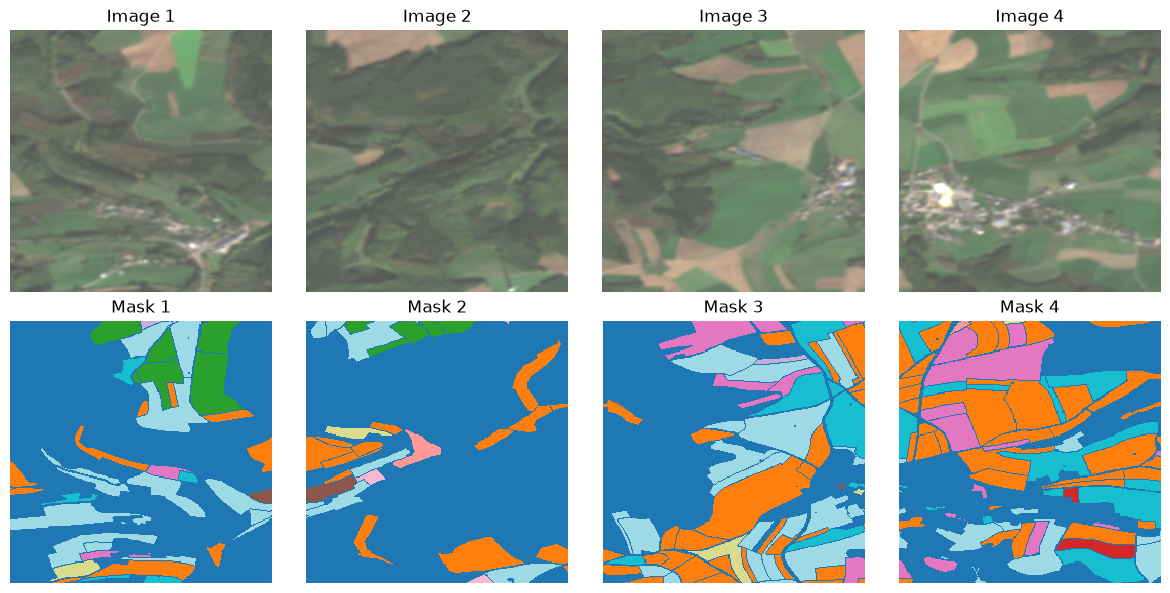

In [3]:
geoai.display_ftw_samples("ftw_data", country="luxembourg", num_samples=4)


Each sample pair displays the Sentinel-2 imagery next to its instance mask. In the mask, each distinct color represents an individual field instance (e.g., $1, 2, 3, \dots$), preserving unique object identities rather than simply labeling all agricultural pixels as a single class.

```{admonition} Temporal Windows (window_a vs. window_b)
:class: note
Each FTW chip includes imagery from two different dates: `window_a` and `window_b`. Because crops mature on varying schedules, two adjacent fields might look identical in spring but display stark spectral contrast after one is harvested in summer:

$$\text{Field A (growing)} \neq \text{Field B (harvested)}$$

Using multi-temporal observations helps algorithms delineate boundaries that are otherwise invisible in a single snapshot.

```

When inspecting samples, perform these manual quality checks:

* Are field boundaries clearly distinguishable in the multi-band imagery?
* Does every instance mask match a plausible agricultural field?
* Do neighboring parcels maintain distinct IDs, or do they merge?

---

### D. Prepare data for training

Before passing data to the Mask R-CNN training pipeline, `prepare_ftw()` handles data rescaling and directory structuring:

In [4]:
data = geoai.prepare_ftw("ftw_data", country="luxembourg")
data


{'images_dir': 'field_boundaries/images',
 'labels_dir': 'field_boundaries/labels',
 'test_dir': 'field_boundaries/test',
 'num_train': 724,
 'num_test': 5}

The preparation pipeline executes four main tasks:

```text
raw FTW imagery (16-bit reflectance, 0-10'000)
                   ↓
   rescale values to 8-bit (0-255 uint8)
                   ↓
organize into standard directory layout (images/ + labels/)
                   ↓
   pool dev chips & reserve test set for inference

```

1. **Reflectance Rescaling:** Converts raw Sentinel-2 16-bit reflectance values (0 - 10'000) to the 8-bit `uint8` range (0 - 255) expected by the underlying `geoai` Mask R-CNN framework. *(Note: This conversion is a specific pipeline requirement for this teaching workflow, not a general rule for all remote sensing tasks).*
2. **Directory Formatting:** Places paired GeoTIFF tiles into standardized subfolders:

```text
field_boundaries/
├── images/
└── labels/

```

3. **Split Reorganization:** Combines the official FTW training and validation chips into a single $724$-chip development pool, while reserving a small, independent test set exclusively for inference demonstrations. An internal validation split ($20\%$) is automatically created from the development pool during model training on the next page.

---

### E. Verify prepared training tiles

Always inspect the formatted output files before starting a long training run to catch preprocessing errors early:

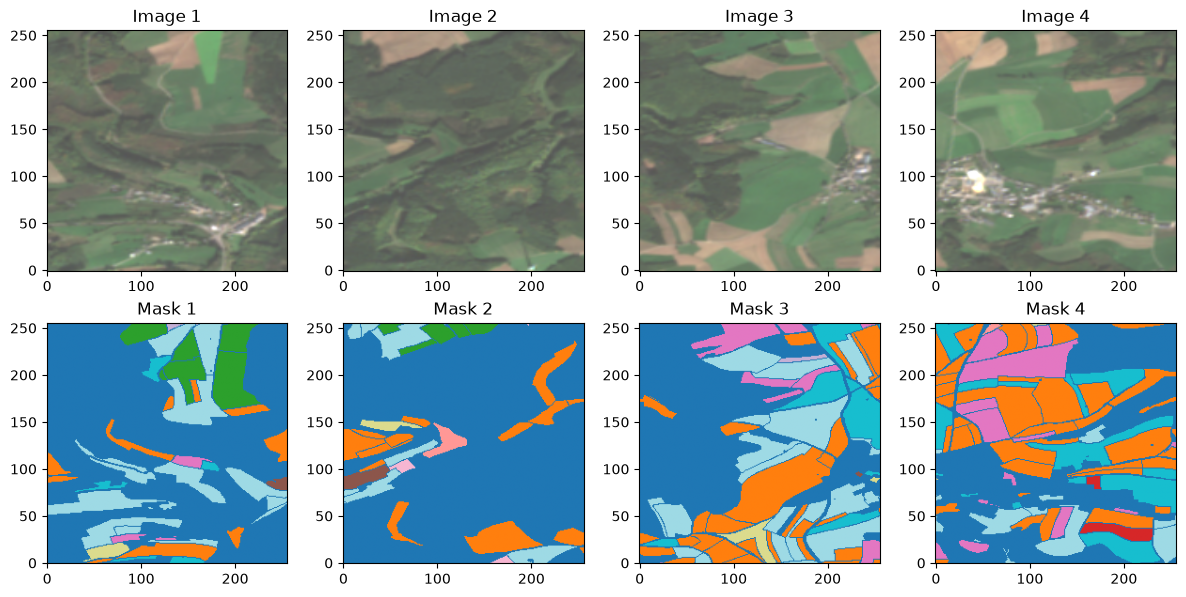

(<Figure size 1200x600 with 8 Axes>,
 array([[<Axes: title={'center': 'Image 1'}>,
         <Axes: title={'center': 'Image 2'}>,
         <Axes: title={'center': 'Image 3'}>,
         <Axes: title={'center': 'Image 4'}>],
        [<Axes: title={'center': 'Mask 1'}>,
         <Axes: title={'center': 'Mask 2'}>,
         <Axes: title={'center': 'Mask 3'}>,
         <Axes: title={'center': 'Mask 4'}>]], dtype=object))

In [5]:
prepared_dir = Path(data["images_dir"]).parent

geoai.display_training_tiles(
    output_dir=str(prepared_dir),
    num_tiles=4,
    figsize=(12, 6),
    cmap="tab20",
)


During this inspection, confirm:

* **Image contrast:** Imagery is clear and not oversaturated or dark.
* **Spatial alignment:** Vector masks align perfectly with underlying imagery features.
* **Instance IDs:** Unique integer IDs are properly preserved across adjacent field boundaries.
* **Data integrity:** No corrupt tiles, missing channels, or unexpected NoData regions exist.

---

## 4. Python reactivation

`Path("ftw_data") / "luxembourg"` uses `pathlib`'s `/` operator to join path components, a cleaner alternative to `os.path.join()` for the same purpose. `gpd.read_parquet()` reads a GeoParquet file into a {term}`GeoDataFrame`, the same object type you have used throughout the course for vector data, just stored in a different, more compact file format than GeoJSON or Shapefile. `chips_gdf["split"].value_counts()` counts how many rows fall into each unique value of the `split` column, a quick way to check a dataset's class or split balance.

---

## 5. Common pitfalls

* **Confusing the official FTW split with `geoai`'s internal validation split.** The official `train`/`val`/`test` column in the metadata is combined into one training pool by `prepare_ftw()`; the `val_split` you will set during training on the next page creates a *separate*, fresh validation split from that pool. These are not the same split.
* **Assuming imagery is already in a usable range.** Raw Sentinel-2 reflectance values (0 to 10,000) are not directly usable as standard 8-bit imagery; `prepare_ftw()` handles this rescaling for you, but it is worth knowing it is happening.
* **Treating `window_a` and `window_b` as redundant duplicates.** They are deliberately different dates, included because seasonal differences carry useful information, not because of a data error.
* **Skipping the visual check in step C.** As in every previous data-preparation page in this course, a quick visual check catches alignment problems that are much harder to diagnose after training.

---

## 6. Mini task

`prepare_ftw()` reported "FTW luxembourg: 808 total chips, Train: 643, Val: 81, Test: 84" and "Using 724 chips for training." Without running any code, explain where the number 724 comes from, and what happens to the 84 test chips mentioned in the first line versus the smaller number `prepare_ftw()` actually sets aside for testing in this tutorial.

:::{dropdown} Sample solution
:class: note

724 is the sum of the official training (643) and validation (81) chips, combined into a single development pool: 643 + 81 = 724. The official split reserves 84 chips for testing, but the tutorial workflow only prepares a small subset of those (5, as shown in the accompanying preparation output) to keep the tutorial lightweight and fast to run; a production workflow would likely use more, or all, of the 84 official test chips for a more robust final evaluation.
:::

---

## 7. Key takeaways

* The FTW dataset provides Sentinel-2 chips with instance-level field-boundary masks already encoded, across 24 countries, with Luxembourg used here as a compact subset.
* `prepare_ftw()` rescales reflectance to `uint8`, organizes files into the expected `images/` and `labels/` structure, and combines the official train and validation chips into one development pool.
* The official FTW split and `geoai`'s internal training-time validation split are two different things; keep them distinct.
* `window_a` and `window_b` are deliberate, different-date captures meant to help with boundary delineation through seasonal contrast.

### Further reading

* Taylor Geospatial, [Fields of The World](https://fieldsofthe.world/) - offcial website including a FTW detector tutorial and explorer app.
* OpenGeoAI, ["Field Boundary Detection"](https://opengeoai.org/examples/field_boundary_detection/) — the full, runnable notebook this workflow is based on.
* [Agricultural Field Boundary Delineation (Instance Segmentation) with GeoAI](https://youtu.be/BT_Uyme_voc) — a video walkthrough of this same dataset and task.